## 2(a)(i)

In [1]:
import sys
import warnings
from time import perf_counter

import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from IPython.display import display
from scipy.optimize import linprog
from scipy.special import expit, logit
from scipy.stats import norm
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, label_binarize,
)
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
SEED = 552
sns.set_theme(style='ticks', font_scale=0.85)
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__, 'SciPy:', scipy.__version__)


Python: 3.13.5
scikit-learn: 1.7.0 SciPy: 1.16.0


In [2]:
from pathlib import Path
import re

import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 50)
pd.set_option('display.precision', 5)

DATA_DIR = Path('data') / 'AReM'
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        'Run this notebook from the folder containing data/AReM.'
    )

channels = [
    'avg_rss12', 'var_rss12', 'avg_rss13',
    'var_rss13', 'avg_rss23', 'var_rss23',
]
activities = [
    'bending1', 'bending2', 'cycling', 'lying',
    'sitting', 'standing', 'walking',
]

records, cleaning = [], []
for activity in activities:
    files = sorted(
        (DATA_DIR / activity).glob('dataset*.csv'),
        key=lambda p: int(re.search(r'dataset(\d+)', p.stem).group(1)),
    )
    for file in files:
        name = file.relative_to(DATA_DIR).as_posix()
        rows, whitespace_rows, trailing_rows = [], 0, 0
        for line in file.read_text(encoding='utf-8-sig').splitlines():
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            whitespace_rows += int(',' not in line)
            trailing_rows += int(line.endswith(','))
            fields = re.split(r'[,\s]+', line.rstrip(',').strip())
            if len(fields) != 7:
                raise ValueError((name, 'Expected seven fields', line))
            rows.append([float(x) for x in fields])

        array = np.asarray(rows)
        if name == 'sitting/dataset8.csv' and array.shape == (479, 7):
            grid = np.arange(0, 120000, 250)
            missing = sorted(set(grid) - set(array[:, 0]))
            assert missing == [13500], missing
            interpolated = [
                np.interp(grid, array[:, 0], array[:, j])
                for j in range(1, 7)
            ]
            array = np.column_stack([grid] + interpolated)
            cleaning.append({
                'file': name,
                'repair': 'Interpolated six values at t=13500',
            })

        assert array.shape == (480, 7), (name, array.shape)
        assert np.isfinite(array).all(), name
        assert (np.diff(array[:, 0]) > 0).all(), name
        number = int(re.search(r'dataset(\d+)', file.stem).group(1))
        records.append({
            'activity': activity,
            'file': name,
            'number': number,
            'values': array[:, 1:],
        })
        if whitespace_rows or trailing_rows:
            cleaning.append({
                'file': name,
                'whitespace_rows': whitespace_rows,
                'trailing_comma_rows': trailing_rows,
            })

assert len(records) == 88
print('Verified: 88 samples, each 480 x 6; all values finite.')
display(pd.DataFrame(cleaning))


Verified: 88 samples, each 480 x 6; all values finite.


,file,whitespace_rows,trailing_comma_rows,repair
0,bending2/dataset4.csv,480.0,0.0,NaN
1,cycling/dataset9.csv,0.0,1.0,NaN
2,cycling/dataset14.csv,0.0,1.0,NaN
3,sitting/dataset8.csv,NaN,NaN,Interpolated six values at t=13500


split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


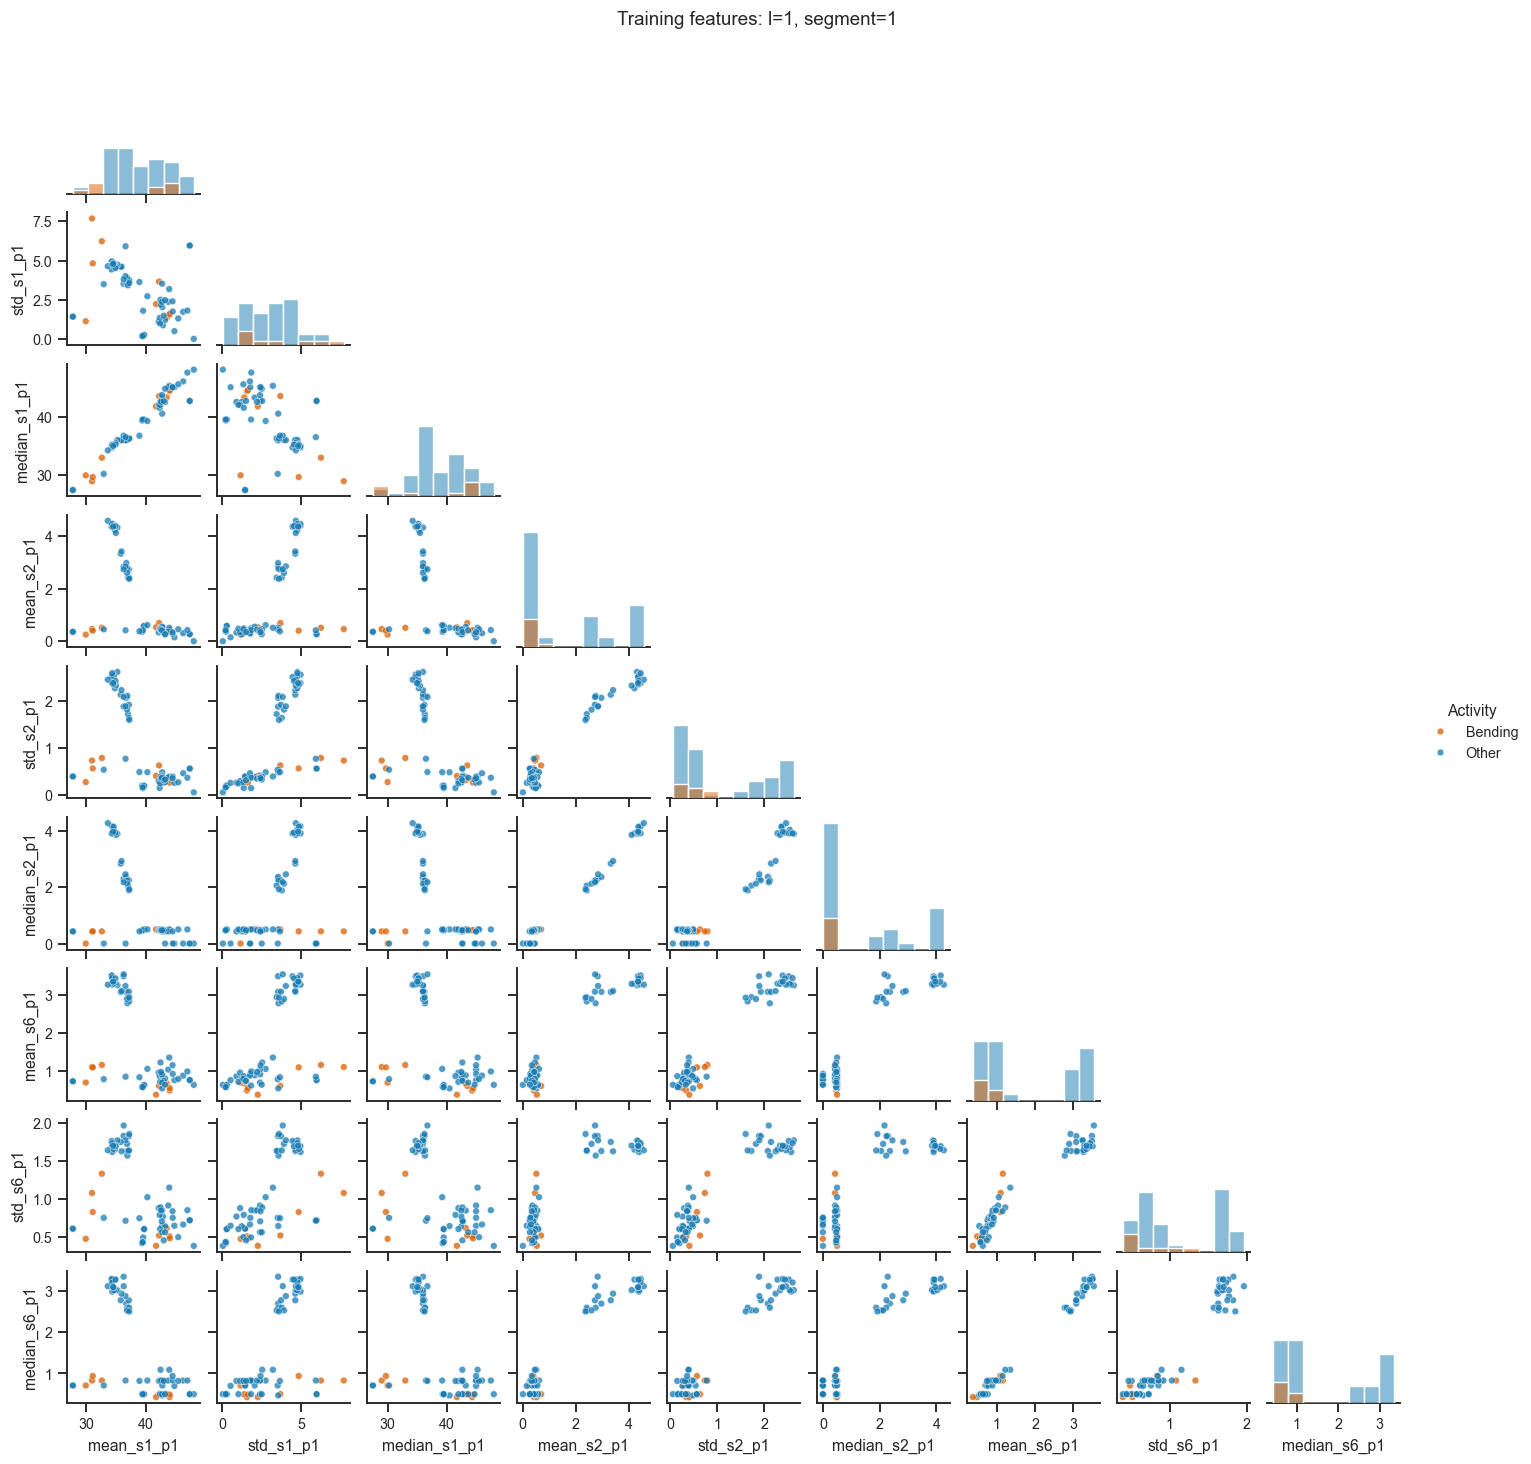

The plotted features are mean, standard deviation, and median from channels 1, 2, and 6, as selected in Homework 3. Only the 69 training records are shown.


In [3]:
metadata = pd.DataFrame([
    {key: record[key] for key in ['activity', 'file', 'number']}
    for record in records
])
metadata['split'] = [
    'test' if record['number'] <= (
        2 if record['activity'].startswith('bending') else 3
    ) else 'train'
    for record in records
]
train_mask = metadata['split'].eq('train').to_numpy()
test_mask = ~train_mask
y_multi = metadata.loc[train_mask, 'activity'].to_numpy()
y_multi_test = metadata.loc[test_mask, 'activity'].to_numpy()
y_binary = np.isin(y_multi, ['bending1', 'bending2']).astype(int)
y_binary_test = np.isin(
    y_multi_test, ['bending1', 'bending2']
).astype(int)
assert train_mask.sum() == 69 and test_mask.sum() == 19
display(pd.crosstab(metadata['activity'], metadata['split']))

def extract_features(segments):
    rows = []
    for record in records:
        row = {}
        chunks = np.array_split(record['values'], segments, axis=0)
        for part, chunk in enumerate(chunks, 1):
            for channel, values in enumerate(chunk.T, 1):
                statistics = {
                    'min': values.min(),
                    'max': values.max(),
                    'mean': values.mean(),
                    'median': np.median(values),
                    'std': values.std(ddof=1),
                    'q1': np.quantile(values, 0.25),
                    'q3': np.quantile(values, 0.75),
                }
                for statistic, value in statistics.items():
                    row[f'{statistic}_s{channel}_p{part}'] = value
        rows.append(row)
    frame = pd.DataFrame(rows)
    assert frame.shape == (88, 42 * segments)
    assert np.isfinite(frame.to_numpy()).all()
    return frame

feature_sets = {segments: extract_features(segments)
                for segments in range(1, 21)}
train_features = {
    segments: frame.loc[train_mask].reset_index(drop=True)
    for segments, frame in feature_sets.items()
}
test_features = {
    segments: frame.loc[test_mask].reset_index(drop=True)
    for segments, frame in feature_sets.items()
}
plot_statistics = ['mean', 'std', 'median']
plot_channels = [1, 2, 6]

def scatter_matrix(segments, part):
    columns = [
        f'{statistic}_s{channel}_p{part}'
        for channel in plot_channels
        for statistic in plot_statistics
    ]
    frame = train_features[segments][columns].copy()
    frame['Activity'] = np.where(y_binary == 1, 'Bending', 'Other')
    grid = sns.pairplot(
        frame, vars=columns, hue='Activity', corner=True,
        diag_kind='hist', height=1.45,
        plot_kws={'s': 20, 'alpha': 0.75},
        palette={'Bending': '#d95f02', 'Other': '#167bb3'},
    )
    grid.figure.suptitle(
        f'Training features: l={segments}, segment={part}', y=1.02
    )
    plt.show()

scatter_matrix(1, 1)
print(
    'The plotted features are mean, standard deviation, and median '
    'from channels 1, 2, and 6, as selected in Homework 3. '
    'Only the 69 training records are shown.'
)


## 2(a)(ii)

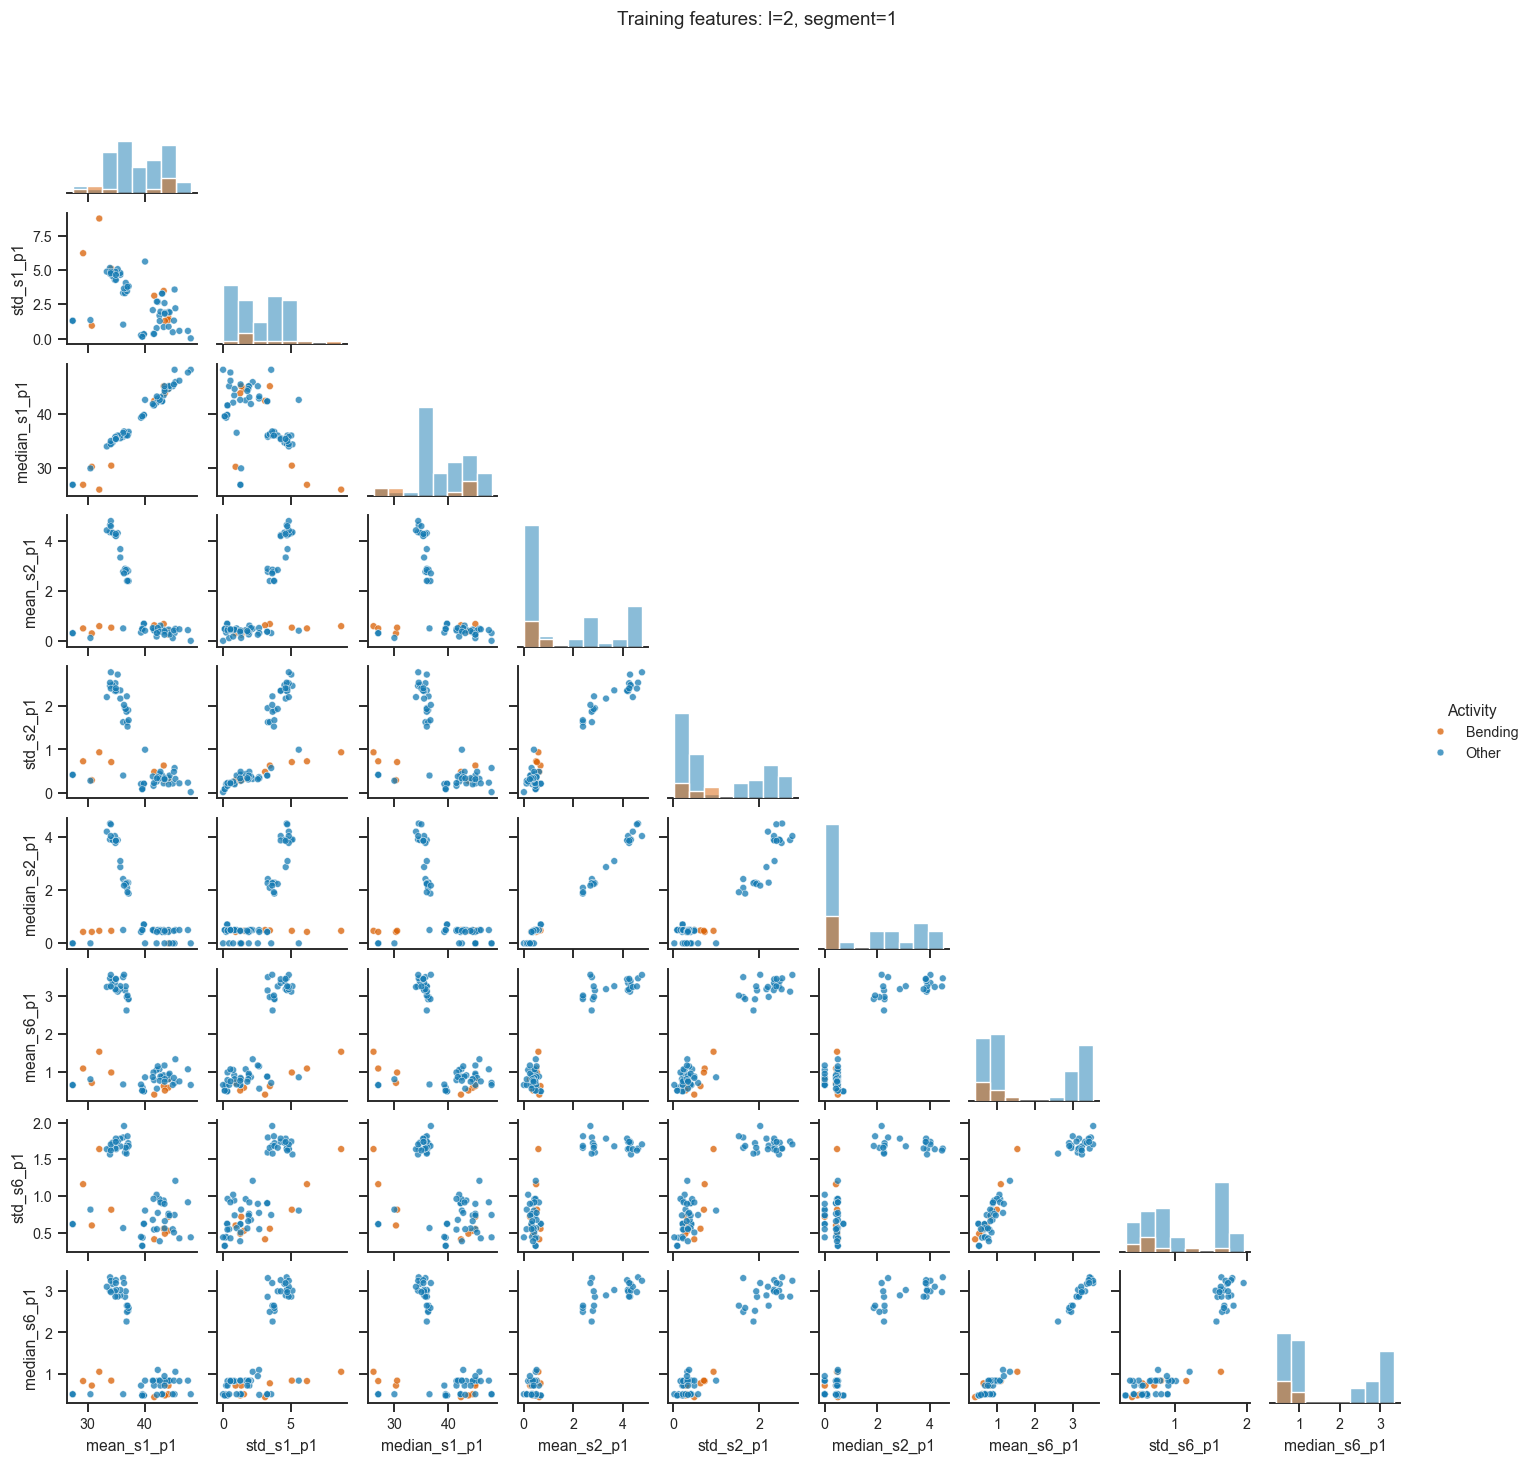

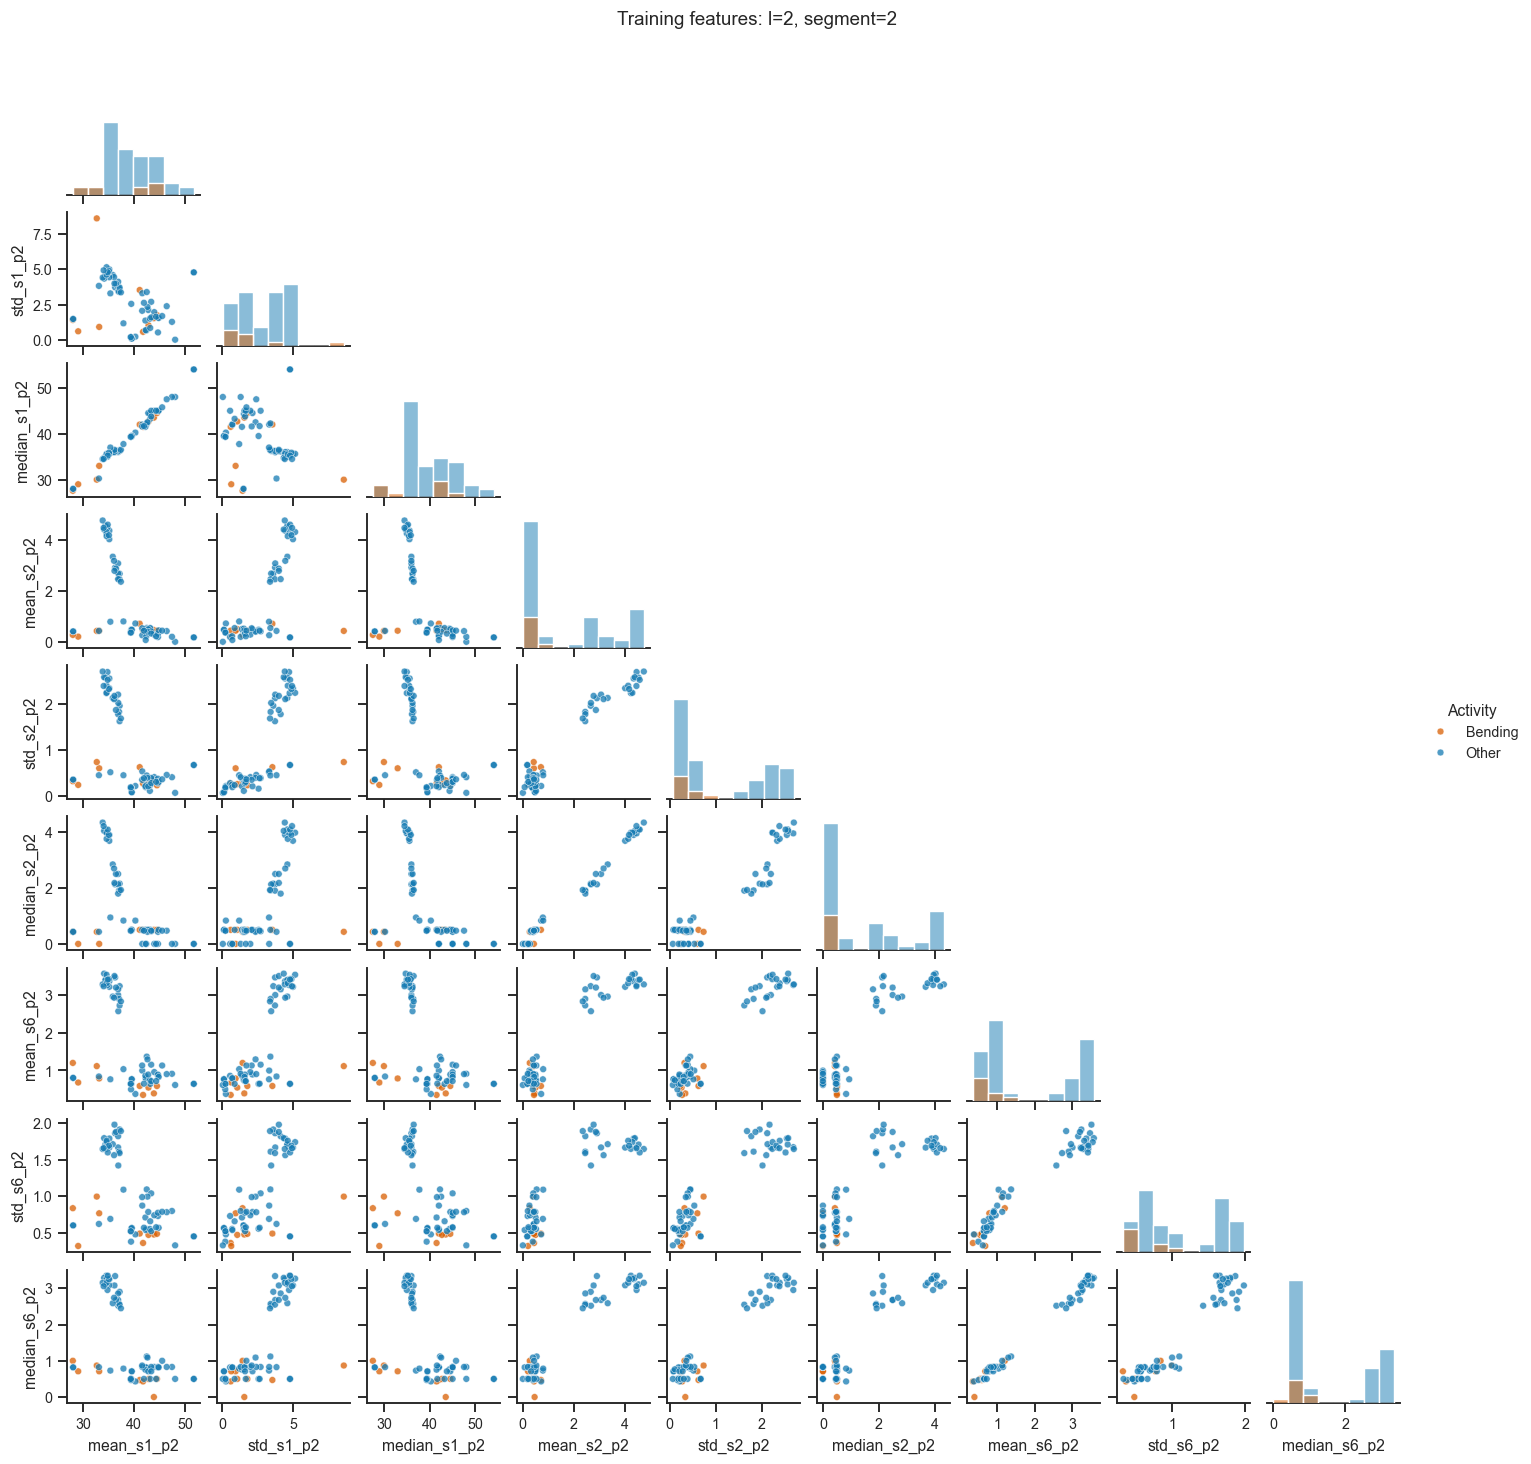

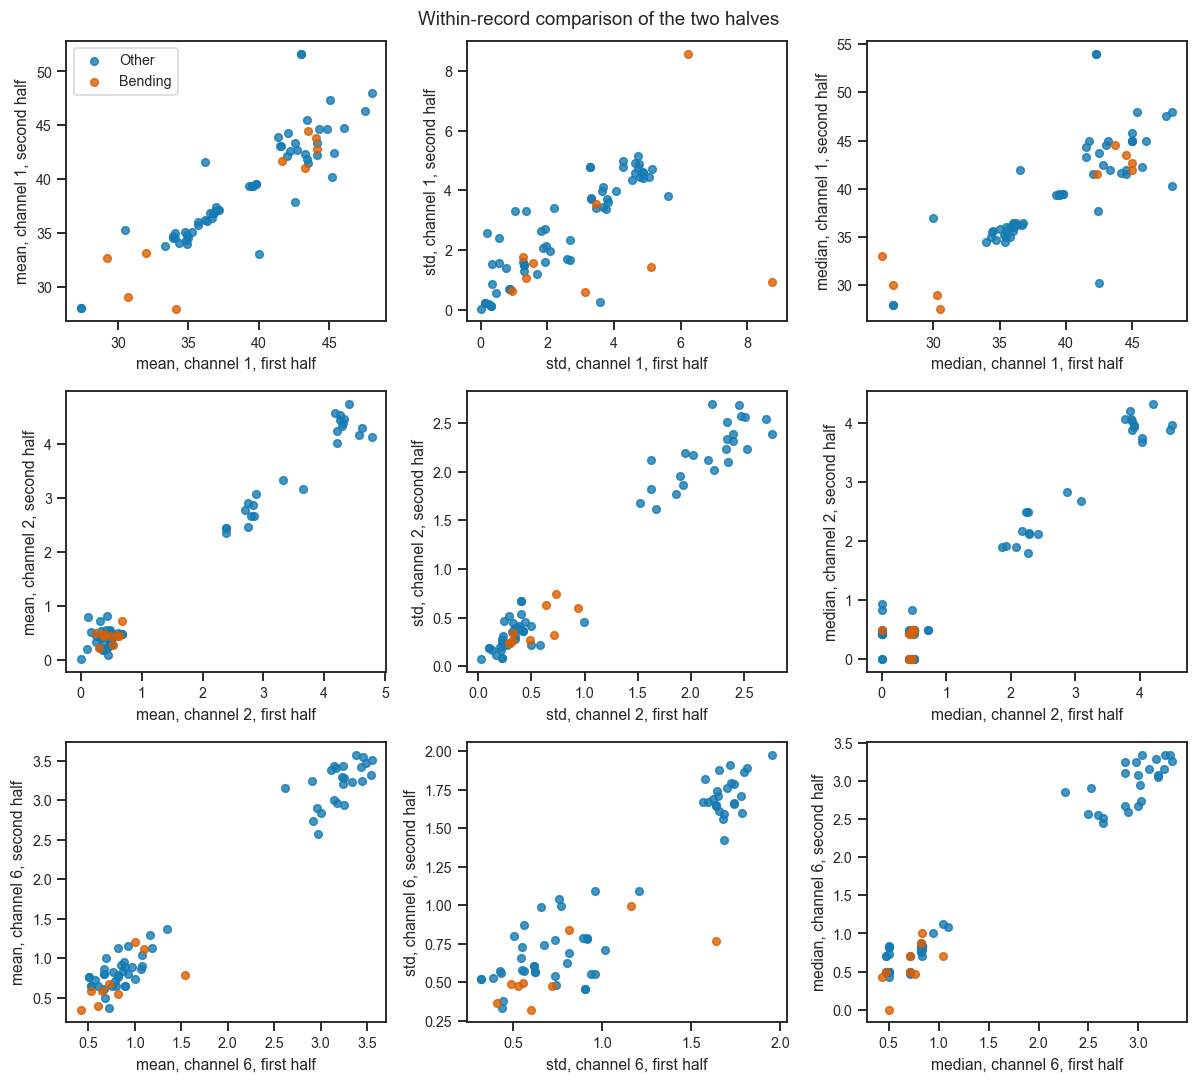

Splitting retains 69 training instances and creates 12 series per instance. The complete feature set grows from 42 to 84; the plotted subset grows from 9 to 18. The plots show each half separately and compare matching features across halves. Segment-specific differences are visible, but overlapping projections remain; splitting alone does not establish a consistent improvement in classification. Cross-validation below evaluates whether the extra temporal detail is useful.


Visually, mean and median of channel 1 remain strongly correlated in both halves. Bending remains concentrated near low mean and median values of channels 2 and 6, with overlap from other activities. Some bending observations have markedly different channel-1 variability between halves. Overall, there is no uniformly clearer separation across these two-dimensional plots.


In [4]:
scatter_matrix(2, 1)
scatter_matrix(2, 2)
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for row, channel in enumerate(plot_channels):
    for col, statistic in enumerate(plot_statistics):
        ax = axes[row, col]
        for label, color, name in [
            (0, '#167bb3', 'Other'), (1, '#d95f02', 'Bending')
        ]:
            mask = y_binary == label
            ax.scatter(
                train_features[2].loc[mask, f'{statistic}_s{channel}_p1'],
                train_features[2].loc[mask, f'{statistic}_s{channel}_p2'],
                c=color, label=name, s=25, alpha=0.8,
            )
        ax.set_xlabel(f'{statistic}, channel {channel}, first half')
        ax.set_ylabel(f'{statistic}, channel {channel}, second half')
axes[0, 0].legend()
fig.suptitle('Within-record comparison of the two halves')
fig.tight_layout()
plt.show()
print(
    'Splitting retains 69 training instances and creates 12 series '
    'per instance. The complete feature set grows from 42 to 84; '
    'the plotted subset grows from 9 to 18. The plots show each '
    'half separately and compare matching features across halves. '
    'Segment-specific differences are visible, but overlapping '
    'projections remain; splitting alone does not establish a '
    'consistent improvement in classification. Cross-validation '
    'below evaluates whether the extra temporal detail is useful.'
)

print(
    'Visually, mean and median of channel 1 remain strongly correlated '
    'in both halves. Bending remains concentrated near low mean and '
    'median values of channels 2 and 6, with overlap from other '
    'activities. Some bending observations have markedly different '
    'channel-1 variability between halves. Overall, there is no '
    'uniformly clearer separation across these two-dimensional plots.'
)


## 2(a)(iii)

In [5]:
binary_cv = list(StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED
).split(np.zeros(len(y_binary)), y_binary))
display(pd.DataFrame([
    {
        'fold': fold,
        'train_bending': int(y_binary[training].sum()),
        'validation_bending': int(y_binary[validation].sum()),
        'validation_other': int((y_binary[validation] == 0).sum()),
    }
    for fold, (training, validation) in enumerate(binary_cv, 1)
]))
print(
    'Correct: keep complete records in folds, extract each record '
    'independently, and fit scaling and RFE on each training fold. '
    'Select l and p using only validation-fold accuracy. '
    'Wrong: select features or fit a scaler on all 69 records before '
    'CV, split one record across folds, or tune on the 19 test records. '
    'Stratification approximately preserves class proportions and '
    'puts bending examples in every binary validation fold. '
    'The maximum tuning CV score can be optimistic after selection; '
    'the held-out test set remains untouched by model selection.'
)
print(
    'RFE is the alternative explicitly permitted by the assignment. '
    'Search: l=1,...,20; p in {1,2,3,5,10,20}. '
    'This is a prespecified candidate grid, not all possible subsets. '
    'RFE removes 20% of the original feature count per step. '
    'The underlying logistic regression has no penalty. '
    'Ties favor fewer selected features, then fewer segments.'
)

def unpenalized_logistic():
    return LogisticRegression(
        penalty=None, solver='lbfgs', max_iter=500,
        tol=1e-6, random_state=SEED,
    )

def rfe_pipeline(count):
    return Pipeline([
        ('scale', StandardScaler()),
        ('rfe', RFE(
            unpenalized_logistic(), n_features_to_select=count,
            step=0.2,
        )),
    ])

def evaluate_cv(model, X, y, folds):
    scores, convergence_count = [], 0
    for training, validation in folds:
        fitted = clone(model)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            fitted.fit(X.iloc[training], y[training])
        convergence_count += sum(
            issubclass(warning.category, ConvergenceWarning)
            for warning in caught
        )
        scores.append(accuracy_score(
            y[validation], fitted.predict(X.iloc[validation])
        ))
    return np.mean(scores), np.std(scores, ddof=1), convergence_count

rfe_rows = []
start = perf_counter()
for segments in range(1, 21):
    for count in [1, 2, 3, 5, 10, 20]:
        mean, deviation, warning_count = evaluate_cv(
            rfe_pipeline(count), train_features[segments],
            y_binary, binary_cv,
        )
        rfe_rows.append({
            'l': segments, 'p': count, 'cv_accuracy': mean,
            'fold_sd': deviation, 'convergence_warnings': warning_count,
        })
    print(f'RFE completed l={segments}')
rfe_results = pd.DataFrame(rfe_rows).sort_values(
    ['cv_accuracy', 'p', 'l'], ascending=[False, True, True]
).reset_index(drop=True)
best_rfe = rfe_results.iloc[0]
rfe_l, rfe_p = int(best_rfe['l']), int(best_rfe['p'])
rfe_model = rfe_pipeline(rfe_p).fit(train_features[rfe_l], y_binary)
display(rfe_results.head(15))
display(rfe_results.groupby('l')['cv_accuracy'].max().to_frame())
print(f'Selected l={rfe_l}, p={rfe_p}; runtime={perf_counter()-start:.1f}s')
print('Total convergence warnings:', rfe_results.convergence_warnings.sum())

print(
    'Reference: https://scikit-learn.org/stable/modules/'
    'cross_validation.html#stratified-k-fold'
)


,fold,train_bending,validation_bending,validation_other
0,1,7,2,12
1,2,7,2,12
2,3,7,2,12
3,4,7,2,12
4,5,8,1,12


Correct: keep complete records in folds, extract each record independently, and fit scaling and RFE on each training fold. Select l and p using only validation-fold accuracy. Wrong: select features or fit a scaler on all 69 records before CV, split one record across folds, or tune on the 19 test records. Stratification approximately preserves class proportions and puts bending examples in every binary validation fold. The maximum tuning CV score can be optimistic after selection; the held-out test set remains untouched by model selection.
RFE is the alternative explicitly permitted by the assignment. Search: l=1,...,20; p in {1,2,3,5,10,20}. This is a prespecified candidate grid, not all possible subsets. RFE removes 20% of the original feature count per step. The underlying logistic regression has no penalty. Ties favor fewer selected features, then fewer segments.
RFE completed l=1
RFE completed l=2
RFE completed l=3
RFE completed l=4
RFE completed l=5
RFE completed l=6
RFE completed

,l,p,cv_accuracy,fold_sd,convergence_warnings
0,14,1,0.98571,0.03194,0
1,1,5,0.97143,0.03912,0
2,7,10,0.97143,0.03912,0
3,10,10,0.97143,0.06389,0
4,6,20,0.97143,0.06389,0
5,3,2,0.95714,0.03912,0
6,1,3,0.95714,0.03912,0
7,2,3,0.95714,0.06389,0
8,3,3,0.95714,0.03912,0
9,9,3,0.95714,0.03912,0


,cv_accuracy
l,
1,0.97143
2,0.95714
3,0.95714
4,0.92747
5,0.94286
6,0.97143
7,0.97143
8,0.92857
9,0.95714


Selected l=14, p=1; runtime=57.2s
Total convergence warnings: 0


Reference: https://scikit-learn.org/stable/modules/cross_validation.html#stratified-k-fold


## 2(a)(iv)

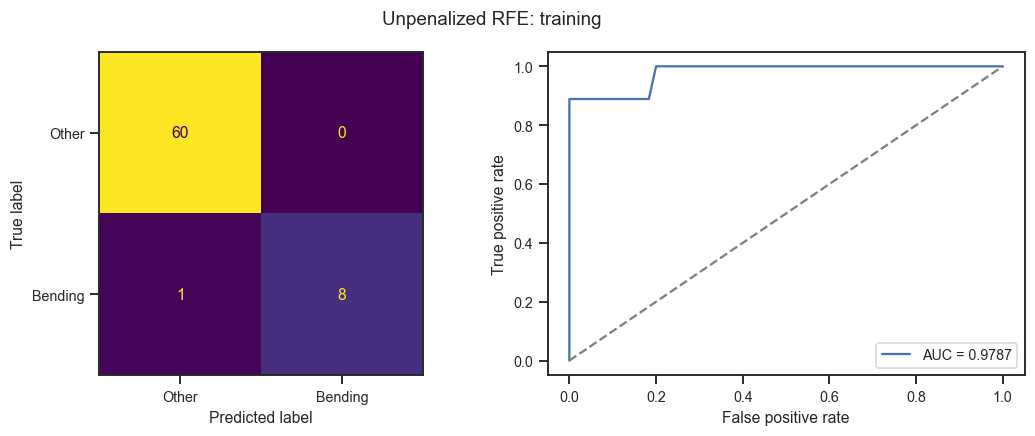

,model,accuracy,balanced_accuracy,f1_bending,auc
0,Unpenalized RFE: training,0.98551,0.94444,0.94118,0.9787


,term,coefficient_standardized,coefficient_original_units,wald_standard_error,wald_p_value
0,Intercept,-4.67118,-12.07715,1.48929,0.00171
1,min_s5_p2,5.27860,0.76800,1.95829,0.00703


Complete separation detected: False
Information matrix condition number: 14.0861327118929
Wald p-values are unavailable (NaN) when complete separation prevents a finite unpenalized MLE or the information matrix is singular/ill-conditioned. Finite solver coefficients are then numerical stopping values, not finite population MLEs. Even when available, ordinary Wald p-values after RFE are exploratory and do not adjust for data-dependent selection.


Numerically valid finite-fit Wald calculation: True


In [6]:
binary_results = []

def binary_report(y, probability, title):
    prediction = (probability >= 0.5).astype(int)
    result = {
        'model': title,
        'accuracy': accuracy_score(y, prediction),
        'balanced_accuracy': balanced_accuracy_score(y, prediction),
        'f1_bending': f1_score(y, prediction, zero_division=0),
        'auc': roc_auc_score(y, probability),
    }
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay.from_predictions(
        y, prediction, labels=[0, 1],
        display_labels=['Other', 'Bending'], ax=axes[0],
        colorbar=False,
    )
    fpr, tpr, _ = roc_curve(y, probability)
    axes[1].plot(fpr, tpr, label=f"AUC = {result['auc']:.4f}")
    axes[1].plot([0, 1], [0, 1], '--', color='gray')
    axes[1].set(xlabel='False positive rate', ylabel='True positive rate')
    axes[1].legend(loc='lower right')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    display(pd.DataFrame([result]))
    return result

rfe_train_probability = rfe_model.predict_proba(
    train_features[rfe_l]
)[:, 1]
rfe_train_report = binary_report(
    y_binary, rfe_train_probability, 'Unpenalized RFE: training'
)
rfe_scaler = rfe_model.named_steps['scale']
rfe_selector = rfe_model.named_steps['rfe']
selected = rfe_selector.support_
selected_names = train_features[rfe_l].columns[selected].tolist()
rfe_estimator = rfe_selector.estimator_
Z = rfe_scaler.transform(train_features[rfe_l])[:, selected]
design = np.column_stack([np.ones(len(Z)), Z])
beta = np.r_[rfe_estimator.intercept_, rfe_estimator.coef_.ravel()]
signs = 2 * y_binary - 1
separation = linprog(
    np.zeros(design.shape[1]),
    A_ub=-signs[:, None] * design,
    b_ub=-np.ones(len(design)),
    bounds=[(None, None)] * design.shape[1], method='highs',
)
is_separated = separation.success
weights = rfe_train_probability * (1 - rfe_train_probability)
information = design.T @ (weights[:, None] * design)
information_condition = np.linalg.cond(information)
wald_valid = (
    not is_separated
    and np.linalg.matrix_rank(information) == design.shape[1]
    and information_condition < 1e12
)
standard_errors = np.full(len(beta), np.nan)
p_values = np.full(len(beta), np.nan)
if wald_valid:
    standard_errors = np.sqrt(np.diag(np.linalg.inv(information)))
    p_values = 2 * norm.sf(np.abs(beta / standard_errors))
raw_slopes = beta[1:] / rfe_scaler.scale_[selected]
raw_intercept = beta[0] - np.dot(
    raw_slopes, rfe_scaler.mean_[selected]
)
coefficient_table = pd.DataFrame({
    'term': ['Intercept'] + selected_names,
    'coefficient_standardized': beta,
    'coefficient_original_units': np.r_[raw_intercept, raw_slopes],
    'wald_standard_error': standard_errors,
    'wald_p_value': p_values,
})
display(coefficient_table)
print('Complete separation detected:', is_separated)
print('Information matrix condition number:', information_condition)
print(
    'Wald p-values are unavailable (NaN) when complete separation '
    'prevents a finite unpenalized MLE or the information matrix is '
    'singular/ill-conditioned. Finite solver coefficients are then '
    'numerical stopping values, not finite population MLEs. '
    'Even when available, ordinary Wald p-values after RFE are '
    'exploratory and do not adjust for data-dependent selection.'
)

print('Numerically valid finite-fit Wald calculation:', wald_valid)


## 2(a)(v)

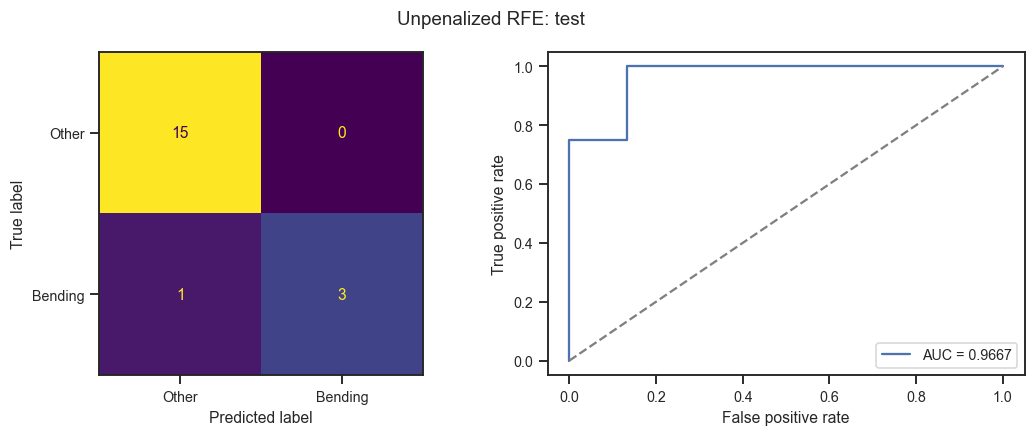

,model,accuracy,balanced_accuracy,f1_bending,auc
0,Unpenalized RFE: test,0.94737,0.875,0.85714,0.96667


,l,p,selected_cv_accuracy,test_accuracy,test_minus_cv
0,14,1,0.98571,0.94737,-0.03835


The test records use the same segmentation, training-fitted scaler, and selected columns. One error among 19 test records changes accuracy by about 5.26 percentage points. The test result is not used to revise l, p, or the decision threshold.


In [7]:
rfe_test_probability = rfe_model.predict_proba(
    test_features[rfe_l]
)[:, 1]
rfe_test_report = binary_report(
    y_binary_test, rfe_test_probability, 'Unpenalized RFE: test'
)
display(pd.DataFrame([{
    'l': rfe_l, 'p': rfe_p,
    'selected_cv_accuracy': best_rfe['cv_accuracy'],
    'test_accuracy': rfe_test_report['accuracy'],
    'test_minus_cv': (
        rfe_test_report['accuracy'] - best_rfe['cv_accuracy']
    ),
}]))
print(
    'The test records use the same segmentation, training-fitted '
    'scaler, and selected columns. One error among 19 test records '
    'changes accuracy by about 5.26 percentage points. The test '
    'result is not used to revise l, p, or the decision threshold.'
)


## 2(a)(vi)

In [8]:
stability_rows = []
for tolerance in [1e-3, 1e-6, 1e-9]:
    model = LogisticRegression(
        penalty=None, solver='lbfgs', max_iter=2000, tol=tolerance
    ).fit(Z, y_binary)
    stability_rows.append({
        'tolerance': tolerance,
        'iterations': int(model.n_iter_[0]),
        'coefficient_norm': np.linalg.norm(model.coef_),
        'train_accuracy': model.score(Z, y_binary),
        'max_abs_logit': np.max(np.abs(model.decision_function(Z))),
    })
display(pd.DataFrame(stability_rows))
if is_separated:
    print(
        'Yes. The linear-program feasibility check confirms complete '
        'separation in the selected training features. Tightening '
        'solver tolerance can enlarge coefficients without improving '
        'classification. The finite unpenalized MLE does not exist; '
        'early stopping gives predictions but does not restore valid '
        'Wald inference. L1 regularization in part (b) gives finite fits.'
    )
else:
    print(
        'The linear-program check did not find complete separation. '
        'Use the coefficient stability table and information-matrix '
        'condition number to assess numerical instability. Near or '
        'quasi-separation can still make inference unreliable.'
    )

if not is_separated:
    print(
        'For the selected model, coefficients are stable when '
        'tolerance tightens from 1e-6 to 1e-9, supporting the absence '
        'of severe instability in this particular final fit. '
        'This does not imply every higher-dimensional candidate '
        'has a finite, stable unpenalized MLE.'
    )


,tolerance,iterations,coefficient_norm,train_accuracy,max_abs_logit
0,1.00000e-03,8,5.01262,0.98551,14.73824
1,1.00000e-06,13,5.27860,0.98551,15.57086
2,1.00000e-09,15,5.27856,0.98551,15.57074


The linear-program check did not find complete separation. Use the coefficient stability table and information-matrix condition number to assess numerical instability. Near or quasi-separation can still make inference unreliable.


For the selected model, coefficients are stable when tolerance tightens from 1e-6 to 1e-9, supporting the absence of severe instability in this particular final fit. This does not imply every higher-dimensional candidate has a finite, stable unpenalized MLE.


## 2(a)(vii)

,n
Other,60
Bending,9


There are 60 controls and 9 cases in training. A majority-only classifier already obtains 60/69 accuracy, so recall, balanced accuracy and ROC AUC are useful alongside ordinary accuracy.


,sample_cases,sample_controls,target_prevalence,sample_prevalence,sample_intercept,intercept_adjustment,adjusted_intercept
0,9,9,0.13043,0.5,0.04098,-1.89712,-1.85614


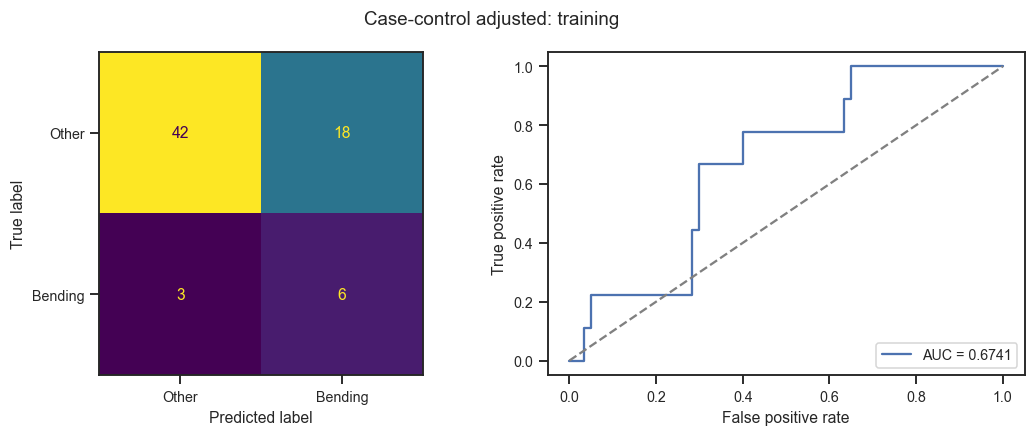

,model,accuracy,balanced_accuracy,f1_bending,auc
0,Case-control adjusted: training,0.69565,0.68333,0.36364,0.67407


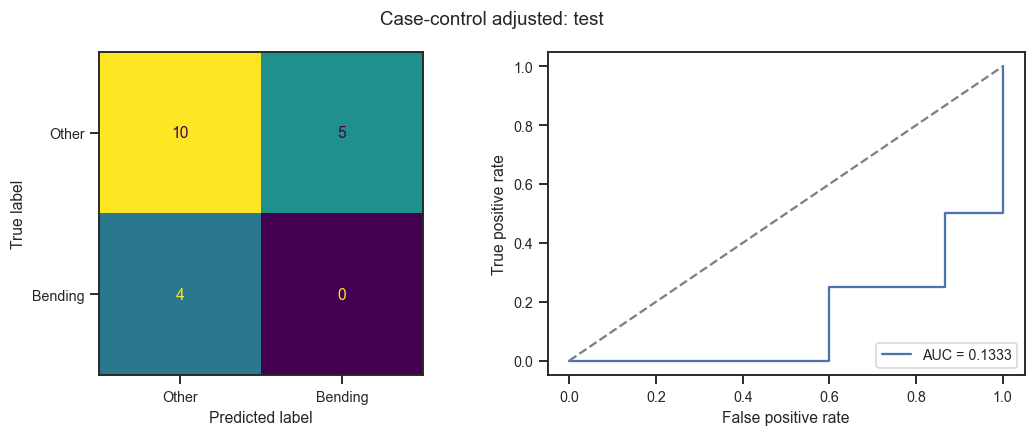

,model,accuracy,balanced_accuracy,f1_bending,auc
0,Case-control adjusted: test,0.52632,0.33333,0.0,0.13333


Controls are sampled randomly within class; cases are retained. The intercept correction is logit(training prevalence) minus logit(sample prevalence), about -1.897. This uses training prevalence as a proxy for the target population prevalence. Its usual calibration justification assumes a correctly specified logistic model and class-dependent sampling. Small samples and separation limit that justification here. The slope estimates are unchanged by the correction; ranking and AUC are unchanged for a fixed fitted model. Sampling can discard useful information.


In [9]:
class_counts = pd.Series(y_binary).value_counts().sort_index()
display(class_counts.rename(index={0: 'Other', 1: 'Bending'}).to_frame('n'))
print(
    'There are 60 controls and 9 cases in training. A majority-only '
    'classifier already obtains 60/69 accuracy, so recall, balanced '
    'accuracy and ROC AUC are useful alongside ordinary accuracy.'
)
rng = np.random.default_rng(SEED)
cases = np.flatnonzero(y_binary == 1)
controls = np.flatnonzero(y_binary == 0)
sampled_controls = rng.choice(controls, size=len(cases), replace=False)
sampled_indices = np.sort(np.r_[cases, sampled_controls])
case_control_model = rfe_pipeline(rfe_p).fit(
    train_features[rfe_l].iloc[sampled_indices],
    y_binary[sampled_indices],
)
target_prevalence = y_binary.mean()
sample_prevalence = y_binary[sampled_indices].mean()
intercept_adjustment = (
    logit(target_prevalence) - logit(sample_prevalence)
)
case_estimator = case_control_model.named_steps['rfe'].estimator_
display(pd.DataFrame([{
    'sample_cases': len(cases),
    'sample_controls': len(sampled_controls),
    'target_prevalence': target_prevalence,
    'sample_prevalence': sample_prevalence,
    'sample_intercept': case_estimator.intercept_[0],
    'intercept_adjustment': intercept_adjustment,
    'adjusted_intercept': (
        case_estimator.intercept_[0] + intercept_adjustment
    ),
}]))
case_probability_train = expit(
    case_control_model.decision_function(train_features[rfe_l])
    + intercept_adjustment
)
case_probability_test = expit(
    case_control_model.decision_function(test_features[rfe_l])
    + intercept_adjustment
)
case_train_report = binary_report(
    y_binary, case_probability_train, 'Case-control adjusted: training'
)
case_test_report = binary_report(
    y_binary_test, case_probability_test, 'Case-control adjusted: test'
)
print(
    'Controls are sampled randomly within class; cases are retained. '
    'The intercept correction is logit(training prevalence) minus '
    'logit(sample prevalence), about -1.897. This uses training '
    'prevalence as a proxy for the target population prevalence. '
    'Its usual calibration justification assumes a correctly specified '
    'logistic model and class-dependent sampling. Small samples and '
    'separation limit that justification here. The slope estimates '
    'are unchanged by the correction; ranking and AUC are unchanged '
    'for a fixed fitted model. Sampling can discard useful information.'
)


## 2(b)(i)

Binary L1 completed l=1
Binary L1 completed l=2
Binary L1 completed l=3
Binary L1 completed l=4
Binary L1 completed l=5
Binary L1 completed l=6
Binary L1 completed l=7
Binary L1 completed l=8
Binary L1 completed l=9
Binary L1 completed l=10
Binary L1 completed l=11
Binary L1 completed l=12
Binary L1 completed l=13
Binary L1 completed l=14
Binary L1 completed l=15
Binary L1 completed l=16
Binary L1 completed l=17
Binary L1 completed l=18
Binary L1 completed l=19
Binary L1 completed l=20


,l,C,cv_accuracy,fold_sd,convergence_warnings
0,11,1.0,0.98571,0.03194,0
1,12,1.0,0.98571,0.03194,0
2,18,10.0,0.98571,0.03194,0
3,19,100.0,0.98571,0.03194,0
4,1,1.0,0.97143,0.03912,0
5,12,10.0,0.97143,0.06389,0
6,12,100.0,0.97143,0.06389,0
7,13,1.0,0.97143,0.03912,0
8,18,1.0,0.97143,0.03912,0
9,18,100.0,0.97143,0.03912,0


,cv_accuracy
l,
1,0.97143
2,0.94286
3,0.95714
4,0.95714
5,0.92747
6,0.92747
7,0.92857
8,0.94286
9,0.92857


Selected l: 11 Selected C: 1.0
Nonzero coefficients: 8
Total convergence warnings: 0


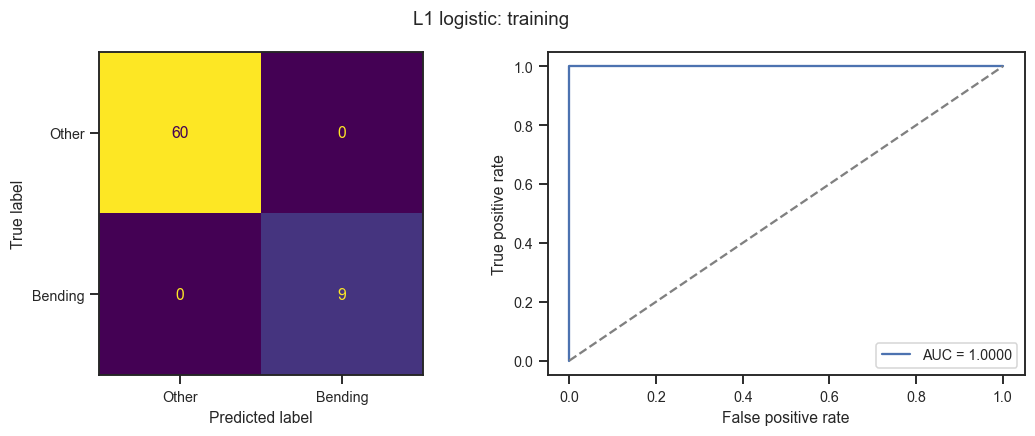

,model,accuracy,balanced_accuracy,f1_bending,auc
0,L1 logistic: training,1.0,1.0,1.0,1.0


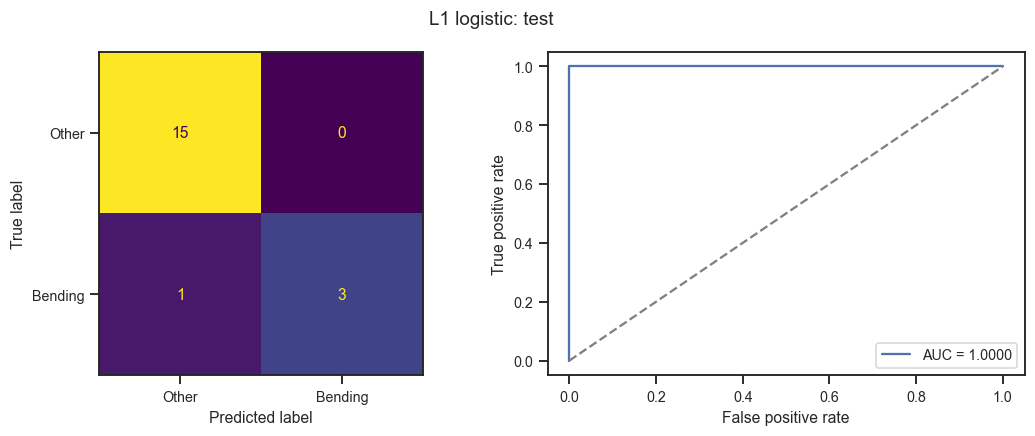

,model,accuracy,balanced_accuracy,f1_bending,auc
0,L1 logistic: test,0.94737,0.875,0.85714,1.0


L1 jointly estimates coefficients and selects features. Smaller C means stronger regularization. The same five binary folds are used as in part (a). Scaling is fitted inside each fold. Ties favor fewer segments, then stronger regularization. The reported optimum is within the stated C grid.


In [10]:
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0]

def l1_binary_pipeline(C):
    return Pipeline([
        ('scale', StandardScaler()),
        ('model', LogisticRegression(
            penalty='l1', solver='liblinear', C=C,
            max_iter=5000, tol=1e-5, random_state=SEED,
        )),
    ])

l1_rows = []
for segments in range(1, 21):
    for C in C_GRID:
        mean, deviation, warning_count = evaluate_cv(
            l1_binary_pipeline(C), train_features[segments],
            y_binary, binary_cv,
        )
        l1_rows.append({
            'l': segments, 'C': C, 'cv_accuracy': mean,
            'fold_sd': deviation, 'convergence_warnings': warning_count,
        })
    print(f'Binary L1 completed l={segments}')
l1_results = pd.DataFrame(l1_rows).sort_values(
    ['cv_accuracy', 'l', 'C'], ascending=[False, True, True]
).reset_index(drop=True)
best_l1 = l1_results.iloc[0]
l1_l, l1_C = int(best_l1['l']), float(best_l1['C'])
l1_model = l1_binary_pipeline(l1_C).fit(
    train_features[l1_l], y_binary
)
display(l1_results.head(15))
display(l1_results.groupby('l')['cv_accuracy'].max().to_frame())
print('Selected l:', l1_l, 'Selected C:', l1_C)
print(
    'Nonzero coefficients:',
    np.count_nonzero(l1_model.named_steps['model'].coef_),
)
print('Total convergence warnings:', l1_results.convergence_warnings.sum())
l1_train_report = binary_report(
    y_binary, l1_model.predict_proba(train_features[l1_l])[:, 1],
    'L1 logistic: training',
)
l1_test_report = binary_report(
    y_binary_test, l1_model.predict_proba(test_features[l1_l])[:, 1],
    'L1 logistic: test',
)
print(
    'L1 jointly estimates coefficients and selects features. '
    'Smaller C means stronger regularization. The same five binary '
    'folds are used as in part (a). Scaling is fitted inside each fold. '
    'Ties favor fewer segments, then stronger regularization. '
    'The reported optimum is within the stated C grid.'
)


## 2(b)(ii)

In [11]:
binary_comparison = pd.DataFrame([
    {
        'method': 'Unpenalized logistic + RFE',
        'cv_accuracy': best_rfe['cv_accuracy'],
        'test_accuracy': rfe_test_report['accuracy'],
        'test_auc': rfe_test_report['auc'],
    },
    {
        'method': 'L1 logistic',
        'cv_accuracy': best_l1['cv_accuracy'],
        'test_accuracy': l1_test_report['accuracy'],
        'test_auc': l1_test_report['auc'],
    },
])
display(binary_comparison)
cv_winners = binary_comparison.loc[
    np.isclose(
        binary_comparison.cv_accuracy,
        binary_comparison.cv_accuracy.max(),
    ), 'method'
].tolist()
print('Best tuning CV accuracy:', ', '.join(cv_winners))
print(
    'Part (a) used the permitted RFE alternative, not p-value pruning; '
    'the empirical comparison therefore concerns RFE versus L1. '
    'L1 is easier to implement because fitting and selection are '
    'combined and no unstable post-selection p-value threshold is '
    'needed. Both searches use the same folds. Test results describe '
    'this fixed split and are not used to tune the methods; small '
    'differences do not establish a statistically reliable winner.'
)

if np.isclose(
    rfe_test_report['accuracy'], l1_test_report['accuracy']
):
    print(
        'The two methods tie on test accuracy: '
        f"{l1_test_report['accuracy']:.4f}. "
        f"Test AUC is {rfe_test_report['auc']:.4f} for RFE and "
        f"{l1_test_report['auc']:.4f} for L1."
    )


,method,cv_accuracy,test_accuracy,test_auc
0,Unpenalized logistic + RFE,0.98571,0.94737,0.96667
1,L1 logistic,0.98571,0.94737,1.00000


Best tuning CV accuracy: Unpenalized logistic + RFE, L1 logistic
Part (a) used the permitted RFE alternative, not p-value pruning; the empirical comparison therefore concerns RFE versus L1. L1 is easier to implement because fitting and selection are combined and no unstable post-selection p-value threshold is needed. Both searches use the same folds. Test results describe this fixed split and are not used to tune the methods; small differences do not establish a statistically reliable winner.


The two methods tie on test accuracy: 0.9474. Test AUC is 0.9667 for RFE and 1.0000 for L1.


## 2(c)(i)

Using 4-fold stratified CV: bending2 has only four training records. Five folds cannot contain every class in every validation fold. All multiclass methods use the same four folds, and the original test split is preserved.


,fold,cycling,sitting,lying,standing,walking,bending1,bending2
0,1,3,3,3,3,3,2,1
1,2,3,3,3,3,3,1,1
2,3,3,3,3,3,3,1,1
3,4,3,3,3,3,3,1,1


Multinomial L1 completed l=1
Multinomial L1 completed l=2
Multinomial L1 completed l=3
Multinomial L1 completed l=4
Multinomial L1 completed l=5
Multinomial L1 completed l=6
Multinomial L1 completed l=7
Multinomial L1 completed l=8
Multinomial L1 completed l=9
Multinomial L1 completed l=10
Multinomial L1 completed l=11
Multinomial L1 completed l=12
Multinomial L1 completed l=13
Multinomial L1 completed l=14
Multinomial L1 completed l=15
Multinomial L1 completed l=16
Multinomial L1 completed l=17
Multinomial L1 completed l=18
Multinomial L1 completed l=19
Multinomial L1 completed l=20


,l,C,cv_accuracy,fold_sd,convergence_warnings
0,2,100.0,0.91258,0.03493,0
1,1,1.0,0.90033,0.08170,0
2,1,100.0,0.89869,0.02849,0
3,2,10.0,0.89869,0.02849,0
4,3,100.0,0.89788,0.03105,0
5,4,100.0,0.89788,0.05719,0
6,2,1.0,0.88644,0.11955,0
7,1,10.0,0.88399,0.00327,0
8,3,10.0,0.88317,0.04937,0
9,4,10.0,0.86928,0.05698,0


,cv_accuracy
l,
1,0.90033
2,0.91258
3,0.89788
4,0.89788
5,0.86846
6,0.85458
7,0.82516
8,0.82435
9,0.84150


Selected l: 2 Selected C: 100.0
Total convergence warnings: 0
SAGA fits the joint multinomial softmax loss with L1 penalty for the seven classes; this is not seven independent binary fits. Confusion-matrix rows are true classes and columns predictions. For ROC evaluation, each class is positive against all others. Macro AUC averages class AUCs equally; micro AUC pools all one-hot labels and scores. OvR here describes evaluation only.
Reference: https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html


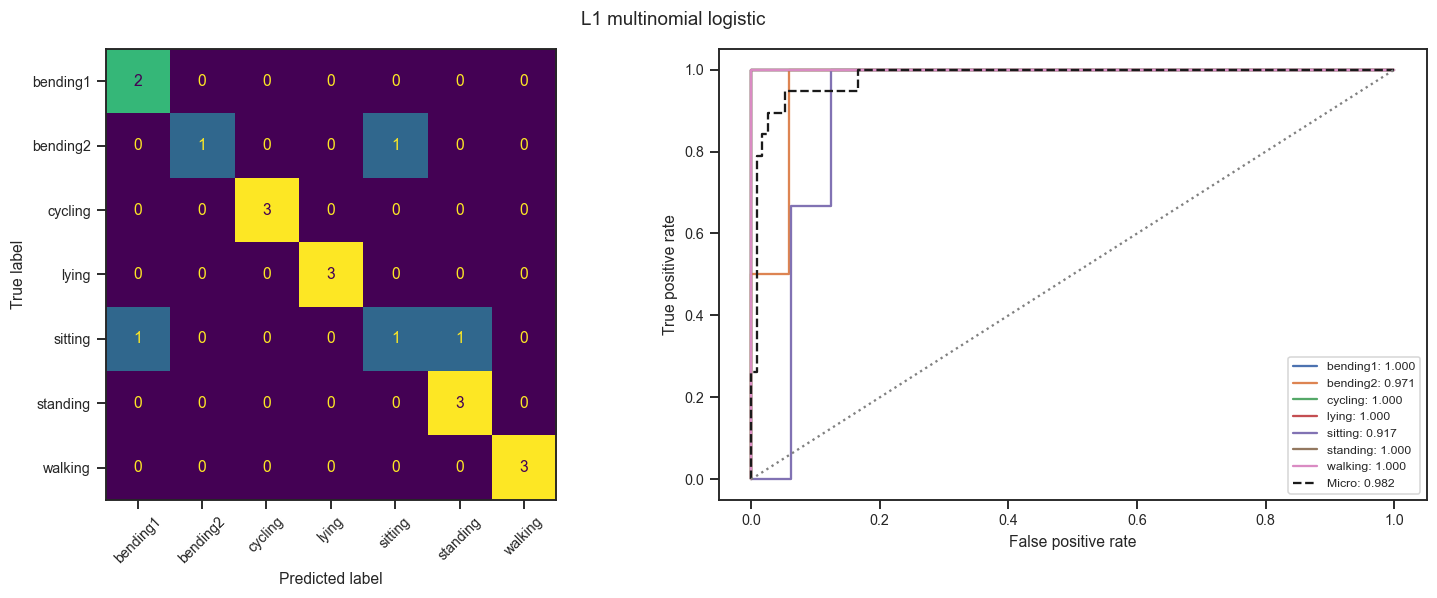

,method,test_accuracy,test_error,test_macro_f1,test_macro_auc,test_micro_auc
0,L1 multinomial logistic,0.84211,0.15789,0.81769,0.98389,0.98153


,class,ovr_auc
0,bending1,1.00000
1,bending2,0.97059
2,cycling,1.00000
3,lying,1.00000
4,sitting,0.91667
5,standing,1.00000
6,walking,1.00000


In [12]:
multi_counts = pd.Series(y_multi).value_counts()
multi_folds = min(5, int(multi_counts.min()))
multi_cv = list(StratifiedKFold(
    n_splits=multi_folds, shuffle=True, random_state=SEED
).split(np.zeros(len(y_multi)), y_multi))
print(
    f'Using {multi_folds}-fold stratified CV: bending2 has only '
    'four training records. Five folds cannot contain every class '
    'in every validation fold. All multiclass methods use the same '
    'four folds, and the original test split is preserved.'
)
display(pd.DataFrame([
    dict(fold=i, **pd.Series(y_multi[validation]).value_counts().to_dict())
    for i, (_, validation) in enumerate(multi_cv, 1)
]).fillna(0))

def multinomial_pipeline(C):
    return Pipeline([
        ('scale', StandardScaler()),
        ('model', LogisticRegression(
            penalty='l1', solver='saga', C=C,
            max_iter=10000, tol=1e-3, random_state=SEED,
        )),
    ])

multinomial_rows = []
for segments in range(1, 21):
    for C in C_GRID:
        mean, deviation, warning_count = evaluate_cv(
            multinomial_pipeline(C), train_features[segments],
            y_multi, multi_cv,
        )
        multinomial_rows.append({
            'l': segments, 'C': C, 'cv_accuracy': mean,
            'fold_sd': deviation, 'convergence_warnings': warning_count,
        })
    print(f'Multinomial L1 completed l={segments}')
multinomial_results = pd.DataFrame(multinomial_rows).sort_values(
    ['cv_accuracy', 'l', 'C'], ascending=[False, True, True]
).reset_index(drop=True)
best_multinomial = multinomial_results.iloc[0]
multi_l = int(best_multinomial['l'])
multi_C = float(best_multinomial['C'])
multinomial_model = multinomial_pipeline(multi_C).fit(
    train_features[multi_l], y_multi
)
display(multinomial_results.head(15))
display(multinomial_results.groupby('l')['cv_accuracy'].max().to_frame())
print('Selected l:', multi_l, 'Selected C:', multi_C)
print(
    'Total convergence warnings:',
    multinomial_results.convergence_warnings.sum(),
)
print(
    'SAGA fits the joint multinomial softmax loss with L1 penalty '
    'for the seven classes; this is not seven independent binary fits. '
    'Confusion-matrix rows are true classes and columns predictions. '
    'For ROC evaluation, each class is positive against all others. '
    'Macro AUC averages class AUCs equally; micro AUC pools all '
    'one-hot labels and scores. OvR here describes evaluation only.'
)
print(
    'Reference: https://scikit-learn.org/stable/'
    'auto_examples/model_selection/plot_roc.html'
)

def multiclass_report(model, X, y, title):
    classes = model.classes_
    probability = model.predict_proba(X)
    prediction = model.predict(X)
    binary_labels = label_binarize(y, classes=classes)
    macro_auc = roc_auc_score(
        y, probability, labels=classes, multi_class='ovr', average='macro'
    )
    micro_auc = roc_auc_score(
        binary_labels.ravel(), probability.ravel()
    )
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y, prediction, labels=classes, ax=axes[0],
        xticks_rotation=45, colorbar=False,
    )
    class_auc = []
    for index, activity in enumerate(classes):
        fpr, tpr, _ = roc_curve(
            binary_labels[:, index], probability[:, index]
        )
        auc = roc_auc_score(
            binary_labels[:, index], probability[:, index]
        )
        class_auc.append({'class': activity, 'ovr_auc': auc})
        axes[1].plot(fpr, tpr, label=f'{activity}: {auc:.3f}')
    fpr, tpr, _ = roc_curve(binary_labels.ravel(), probability.ravel())
    axes[1].plot(
        fpr, tpr, 'k--', label=f'Micro: {micro_auc:.3f}'
    )
    axes[1].plot([0, 1], [0, 1], ':', color='gray')
    axes[1].set(xlabel='False positive rate', ylabel='True positive rate')
    axes[1].legend(fontsize=8, loc='lower right')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    result = {
        'method': title,
        'test_accuracy': accuracy_score(y, prediction),
        'test_error': 1 - accuracy_score(y, prediction),
        'test_macro_f1': f1_score(y, prediction, average='macro'),
        'test_macro_auc': macro_auc, 'test_micro_auc': micro_auc,
    }
    display(pd.DataFrame([result]))
    display(pd.DataFrame(class_auc))
    return result

multinomial_report = multiclass_report(
    multinomial_model, test_features[multi_l], y_multi_test,
    'L1 multinomial logistic',
)


## 2(c)(ii)

Gaussian and multinomial refer to feature likelihoods, not class priors. Both models estimate class priors from training folds. GaussianNB models continuous class-conditional features. MultinomialNB expects nonnegative count-like features; these sensor summaries are continuous, so it is an approximation. For MultinomialNB, MinMaxScaler is fitted within each fold and clips held-out values to [0,1] to guarantee nonnegativity. GaussianNB uses training-fitted standardization and smoothing. Overlapping summary statistics violate strict conditional independence, particularly mean, median, and quartiles.
GaussianNB selected l: 1 parameter: 0.1


,l,parameter,cv_accuracy,fold_sd
0,1,1.00000e-01,0.92729,0.07425
1,2,1.00000e-03,0.88480,0.04412
2,1,1.00000e-06,0.88480,0.06522
3,2,1.00000e-01,0.88317,0.06888
4,5,1.00000e-01,0.88317,0.04937
5,7,1.00000e-01,0.88317,0.06888
6,1,1.00000e-03,0.87092,0.08325
7,1,1.00000e-09,0.87010,0.05392
8,16,1.00000e-01,0.86928,0.05698
9,8,1.00000e-01,0.86846,0.05775


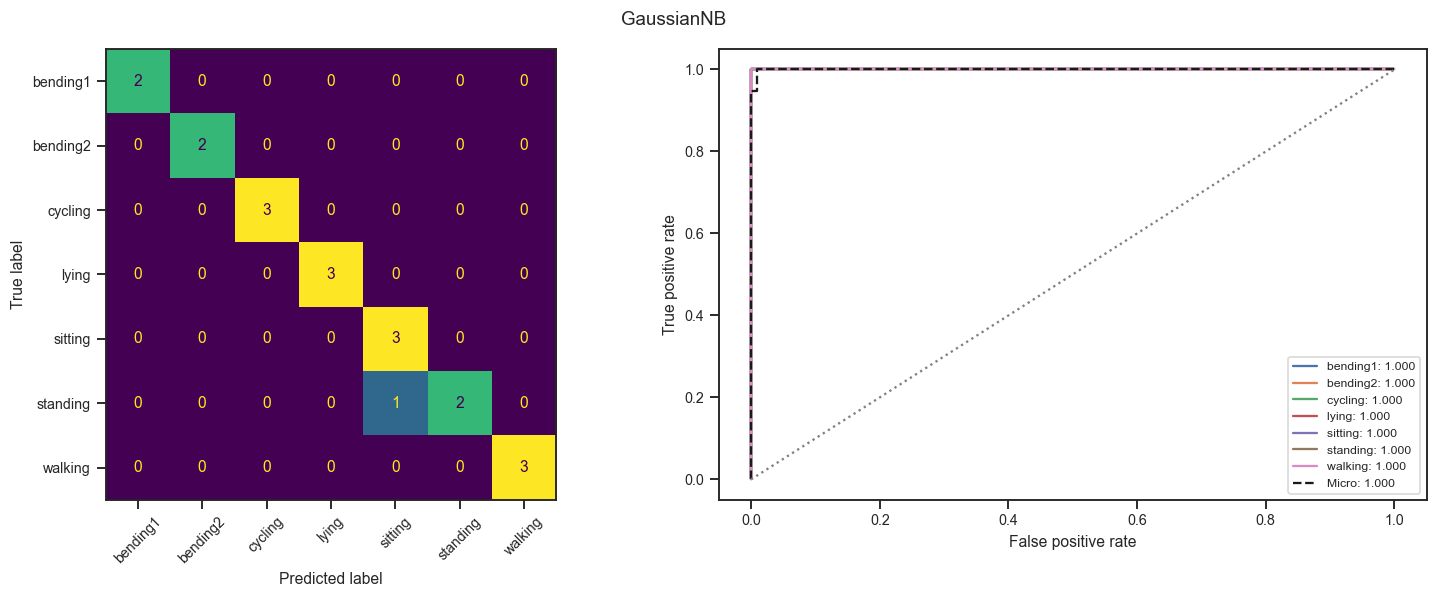

,method,test_accuracy,test_error,test_macro_f1,test_macro_auc,test_micro_auc
0,GaussianNB,0.94737,0.05263,0.95102,1.0,0.99954


,class,ovr_auc
0,bending1,1.0
1,bending2,1.0
2,cycling,1.0
3,lying,1.0
4,sitting,1.0
5,standing,1.0
6,walking,1.0


MultinomialNB selected l: 1 parameter: 0.01


,l,parameter,cv_accuracy,fold_sd
0,1,0.01,0.82680,0.14245
1,10,0.10,0.82598,0.09618
2,20,0.01,0.82598,0.04828
3,2,0.01,0.81209,0.05320
4,15,0.01,0.81209,0.09874
5,17,0.01,0.81209,0.09874
6,19,0.01,0.81209,0.09874
7,10,0.01,0.81127,0.07483
8,1,0.10,0.79820,0.13680
9,12,0.10,0.79820,0.13680


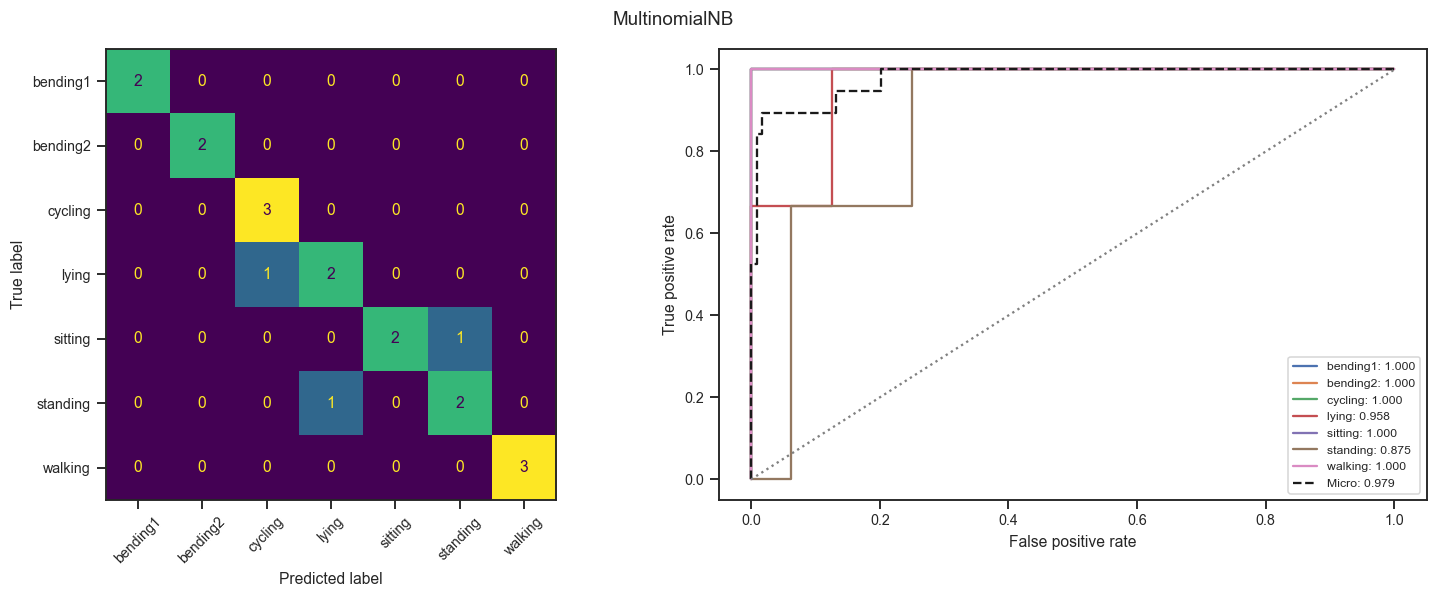

,method,test_accuracy,test_error,test_macro_f1,test_macro_auc,test_micro_auc
0,MultinomialNB,0.84211,0.15789,0.85578,0.97619,0.97876


,class,ovr_auc
0,bending1,1.00000
1,bending2,1.00000
2,cycling,1.00000
3,lying,0.95833
4,sitting,1.00000
5,standing,0.87500
6,walking,1.00000


Reference: https://scikit-learn.org/stable/modules/naive_bayes.html


In [13]:
print(
    'Gaussian and multinomial refer to feature likelihoods, not '
    'class priors. Both models estimate class priors from training '
    'folds. GaussianNB models continuous class-conditional features. '
    'MultinomialNB expects nonnegative count-like features; these '
    'sensor summaries are continuous, so it is an approximation. '
    'For MultinomialNB, MinMaxScaler is fitted within each fold and '
    'clips held-out values to [0,1] to guarantee nonnegativity. '
    'GaussianNB uses training-fitted standardization and smoothing. '
    'Overlapping summary statistics violate strict conditional '
    'independence, particularly mean, median, and quartiles.'
)

def nb_pipeline(kind, parameter):
    if kind == 'GaussianNB':
        return Pipeline([
            ('scale', StandardScaler()),
            ('model', GaussianNB(var_smoothing=parameter)),
        ])
    return Pipeline([
        ('scale', MinMaxScaler(clip=True)),
        ('model', MultinomialNB(alpha=parameter)),
    ])

nb_results = {}
nb_models = {}
nb_reports = {}
nb_best = {}
for kind, parameters in [
    ('GaussianNB', [1e-9, 1e-6, 1e-3, 0.1]),
    ('MultinomialNB', [0.01, 0.1, 1.0, 10.0]),
]:
    rows = []
    for segments in range(1, 21):
        for parameter in parameters:
            mean, deviation, warning_count = evaluate_cv(
                nb_pipeline(kind, parameter), train_features[segments],
                y_multi, multi_cv,
            )
            rows.append({
                'l': segments, 'parameter': parameter,
                'cv_accuracy': mean, 'fold_sd': deviation,
            })
    results = pd.DataFrame(rows).sort_values(
        ['cv_accuracy', 'l', 'parameter'],
        ascending=[False, True, True],
    ).reset_index(drop=True)
    best = results.iloc[0]
    segments, parameter = int(best['l']), float(best['parameter'])
    fitted = nb_pipeline(kind, parameter).fit(
        train_features[segments], y_multi
    )
    nb_results[kind] = results
    nb_models[kind] = fitted
    nb_best[kind] = best
    print(kind, 'selected l:', segments, 'parameter:', parameter)
    display(results.head(10))
    nb_reports[kind] = multiclass_report(
        fitted, test_features[segments], y_multi_test, kind
    )

print(
    'Reference: https://scikit-learn.org/stable/modules/'
    'naive_bayes.html'
)


## 2(c)(iii)

In [14]:
multiclass_comparison = pd.DataFrame([
    dict(
        multinomial_report,
        cv_accuracy=best_multinomial['cv_accuracy'],
        l=multi_l,
    ),
    *[
        dict(
            nb_reports[kind],
            cv_accuracy=nb_best[kind]['cv_accuracy'],
            l=int(nb_best[kind]['l']),
        )
        for kind in ['GaussianNB', 'MultinomialNB']
    ],
])
display(multiclass_comparison)
best_cv = multiclass_comparison.loc[
    np.isclose(
        multiclass_comparison.cv_accuracy,
        multiclass_comparison.cv_accuracy.max(),
    ), 'method'
].tolist()
best_test = multiclass_comparison.loc[
    np.isclose(
        multiclass_comparison.test_error,
        multiclass_comparison.test_error.min(),
    ), 'method'
].tolist()
print('Preferred by training CV accuracy:', ', '.join(best_cv))
print('Lowest observed test error:', ', '.join(best_test))
print(
    'These conclusions apply to this split and the specified grids. '
    'Model selection should follow training CV rather than repeated '
    'inspection of test accuracy. The 19-record test set is small, '
    'with only two bending records per subtype; small differences '
    'are not evidence of a universal performance ranking. '
    'No held-out labels were used for feature selection or tuning.'
)
assert len(records) == 88
assert all(frame.shape[0] == 69 for frame in train_features.values())
assert all(frame.shape[0] == 19 for frame in test_features.values())
assert rfe_results['l'].nunique() == 20
assert l1_results['l'].nunique() == 20
assert multinomial_results['l'].nunique() == 20
print('All Part 2 calculations completed.')


,method,test_accuracy,test_error,test_macro_f1,test_macro_auc,test_micro_auc,cv_accuracy,l
0,L1 multinomial logistic,0.84211,0.15789,0.81769,0.98389,0.98153,0.91258,2
1,GaussianNB,0.94737,0.05263,0.95102,1.00000,0.99954,0.92729,1
2,MultinomialNB,0.84211,0.15789,0.85578,0.97619,0.97876,0.82680,1


Preferred by training CV accuracy: GaussianNB
Lowest observed test error: GaussianNB
These conclusions apply to this split and the specified grids. Model selection should follow training CV rather than repeated inspection of test accuracy. The 19-record test set is small, with only two bending records per subtype; small differences are not evidence of a universal performance ranking. No held-out labels were used for feature selection or tuning.
All Part 2 calculations completed.


## ISLR 4.8.3

Let $\pi_k=P(Y=k)$ denote the prior probability of class $k$. Assume that

$$
X\mid Y=k\sim N(\mu_k,\sigma_k^2).
$$

By Bayes' theorem,

$$
P(Y=k\mid X=x)
=
\frac{\pi_k f_k(x)}
{\sum_{j=1}^{K}\pi_j f_j(x)}.
$$

Since the denominator is identical for all classes, the Bayes classifier
assigns $x$ to the class maximizing $\log(\pi_k f_k(x))$.

Substituting the normal density and dropping the common constant
$-\frac12\log(2\pi)$ gives

$$
\delta_k(x)
=
\log\pi_k-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term,

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log\sigma_k+\log\pi_k.
$$

When class variances differ, the coefficient of $x^2$ depends on the
class and cannot generally be removed when comparing classes.
Consequently, the equation $\delta_k(x)=\delta_j(x)$ defining a
pairwise decision boundary is generally quadratic in $x$.

Therefore, the Bayes classifier uses quadratic rather than linear
discriminant functions. If all class variances are equal, the
quadratic terms cancel, yielding the linear discriminant rule of LDA.

## ISLR 4.8.7

The given parameters are

$$
\pi_{\text{Yes}}=0.8,\qquad
\pi_{\text{No}}=0.2,
$$

$$
\mu_{\text{Yes}}=10,\qquad
\mu_{\text{No}}=0,\qquad
\sigma^2=36.
$$

By Bayes' theorem,

$$
P(\text{Yes}\mid X=4)
=
\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}.
$$

Both normal densities have the same variance, so their common
normalization factor cancels. Therefore,

$$
\begin{aligned}
P(\text{Yes}\mid X=4)
&=
\frac{
0.8\exp\left(-\frac{(4-10)^2}{72}\right)
}{
0.8\exp\left(-\frac{(4-10)^2}{72}\right)
+
0.2\exp\left(-\frac{(4-0)^2}{72}\right)
}\\[4pt]
&=
\frac{0.8e^{-1/2}}
{0.8e^{-1/2}+0.2e^{-2/9}}\\[4pt]
&=
\frac{1}{1+0.25e^{5/18}}\\[4pt]
&\approx 0.7519.
\end{aligned}
$$

The estimated probability that the company will issue a dividend
is therefore approximately 75.2%.

Using a classification threshold of $0.5$, we predict Yes.